<a href="https://colab.research.google.com/github/Ridima28/Plant-Disease-Prediction-with-CNN/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import random
random.seed(0)

import numpy as np
np.random.seed(0)

import tensorflow as tf
tf.random.set_seed(0)

In [50]:
from IPython.core.display import Image
import os
import json
from zipfile import ZipFile
from PIL import Image

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

In [29]:
kaggle_creds = json.load(open('/content/kaggle.json'))
os.environ['KAGGLE_USERNAME'] = kaggle_creds['username']
os.environ['KAGGLE_KEY'] = kaggle_creds['key']

In [30]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
plantvillage-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [31]:
with ZipFile("plantvillage-dataset.zip", 'r') as zip_ref:
  zip_ref.extractall()

In [32]:

print(os.listdir("plantvillage dataset"))


print(len(os.listdir("plantvillage dataset/segmented")))
print(os.listdir("plantvillage dataset/segmented")[:5])

print(len(os.listdir("plantvillage dataset/color")))
print(os.listdir("plantvillage dataset/color")[:5])

print(len(os.listdir("plantvillage dataset/grayscale")))
print(os.listdir("plantvillage dataset/grayscale")[:5])

['color', 'segmented', 'grayscale']
38
['Apple___Black_rot', 'Grape___healthy', 'Apple___healthy', 'Apple___Apple_scab', 'Tomato___Early_blight']
38
['Apple___Black_rot', 'Grape___healthy', 'Apple___healthy', 'Apple___Apple_scab', 'Tomato___Early_blight']
38
['Apple___Black_rot', 'Grape___healthy', 'Apple___healthy', 'Apple___Apple_scab', 'Tomato___Early_blight']


Total classes:3

In [33]:
print(len(os.listdir("plantvillage dataset/color/Grape___healthy")))
print(os.listdir("plantvillage dataset/color/Grape___healthy")[:5])

423
['18fd5d50-f80c-426c-bfdb-5ca325065f24___Mt.N.V_HL 6024.JPG', '61a531ba-3d52-4af3-8828-c2dbba4d3b1d___Mt.N.V_HL 8941.JPG', 'ef0cd637-5b34-489e-affc-72cce3dbc901___Mt.N.V_HL 6138.JPG', '7c10d5ab-f960-4fa6-a965-8c825df24810___Mt.N.V_HL 9041.JPG', '8fc498ea-cad4-48cd-9fea-af07f803a63b___Mt.N.V_HL 6198.JPG']


Data Preprocessing

In [34]:
# Dataset Path
base_dir = 'plantvillage dataset/color'

(256, 256, 3)


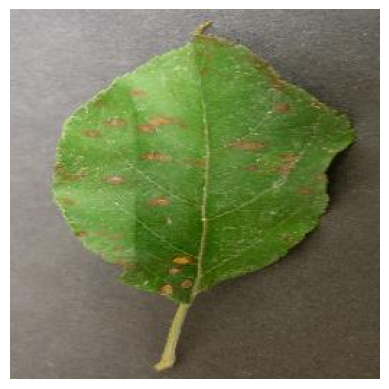

In [35]:

image_path = '/content/plantvillage dataset/color/Apple___Cedar_apple_rust/025b2b9a-0ec4-4132-96ac-7f2832d0db4a___FREC_C.Rust 3655.JPG'

# Read the image
img = mpimg.imread(image_path)

print(img.shape)
# Display the image
plt.imshow(img)
plt.axis('off')  # Turn off axis numbers
plt.show()

In [38]:
#Img params
img_size = 224 #shape should remain same
batch_size = 32

Train-Test Split

In [74]:
data_gen = ImageDataGenerator( rescale = 1/255, validation_split=0.2)

In [75]:
#Train Generetor

train_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='training',
    class_mode = 'categorical'
)

Found 43456 images belonging to 38 classes.


In [76]:
#Validation Generetor

validation_generator = data_gen.flow_from_directory(
    base_dir,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    subset='validation',
    class_mode = 'categorical'
)

Found 10849 images belonging to 38 classes.


CNN

In [77]:
model  = models.Sequential()


input_shape = (224, 224, 3)
n_classes = len(train_generator.class_indices)

model.add(layers.Conv2D(filters=64, kernel_size=(7, 7), strides=(3, 3), activation='relu', input_shape=input_shape))
model.add(layers.MaxPool2D(pool_size=(3, 3)))

model.add(layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))

model.add(layers.Conv2D(filters=256, kernel_size=(3, 3), activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=(2, 2)))


model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(256, activation='relu'))

model.add(layers.Dropout(0.5))

model.add(layers.Dense(n_classes, activation='softmax'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [78]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 73, 73, 64)     │         9,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 3, 3, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 1, 1, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,257,510 (4.80 MB)

 Trainable params: 1,257,510 (4.80 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
model.compile(optimizer='adam', loss= 'categorical_crossentropy', metrics=['accuracy'])

In [ ]:

history = model.fit(
    train_generator,
    batch_size=32,
    validation_data=validation_generator,
    epochs=30
)

Epoch 1/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 133s 94ms/step - accuracy: 0.4099 - loss: 2.1551 - val_accuracy: 0.6814 - val_loss: 1.0407
Epoch 2/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 125s 92ms/step - accuracy: 0.7476 - loss: 0.8320 - val_accuracy: 0.8136 - val_loss: 0.5960
Epoch 3/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 130s 95ms/step - accuracy: 0.8337 - loss: 0.5362 - val_accuracy: 0.8516 - val_loss: 0.4627
Epoch 4/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 127s 94ms/step - accuracy: 0.8804 - loss: 0.3871 - val_accuracy: 0.8734 - val_loss: 0.4083
Epoch 5/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 119s 87ms/step - accuracy: 0.9061 - loss: 0.3063 - val_accuracy: 0.8972 - val_loss: 0.3333
Epoch 6/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 117s 86ms/step - accuracy: 0.9181 - loss: 0.2610 - val_accuracy: 0.9053 - val_loss: 0.3107
Epoch 7/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 123s 91ms/step - accuracy: 0.9336 - loss: 0.2160 - val_accuracy: 0.9176 - val_loss: 0.2740
Epoch 8/30
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 125s 92ms/step - accuracy: 

In [70]:

# Model Evaluation
print("Evaluating model...")
val_loss, val_accuracy = model.evaluate(validation_generator, steps=validation_generator.samples // batch_size)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")


Evaluating model...
508/508 ━━━━━━━━━━━━━━━━━━━━ 35s 70ms/step - accuracy: 0.9062 - loss: 0.6201
Validation Accuracy: 90.62%


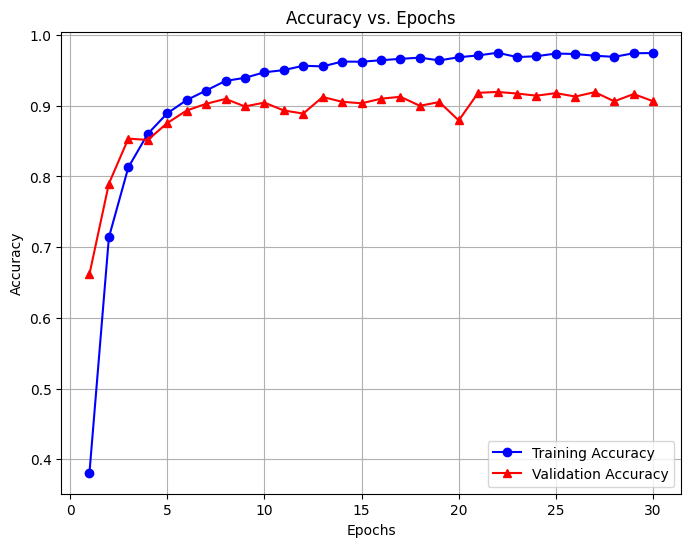

In [71]:
import matplotlib.pyplot as plt

# Extract Accuracy and Validation Accuracy from history
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(train_acc) + 1)  # Number of epochs

# Plot Training and Validation Accura cy
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_acc, 'bo-', label='Training Accuracy')  # 'bo-' means blue circles with lines
plt.plot(epochs, val_acc, 'r^-', label='Validation Accuracy')  # 'r^-' means red triangles with lines

plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Epochs')
plt.legend()
plt.grid(True)
plt.show()

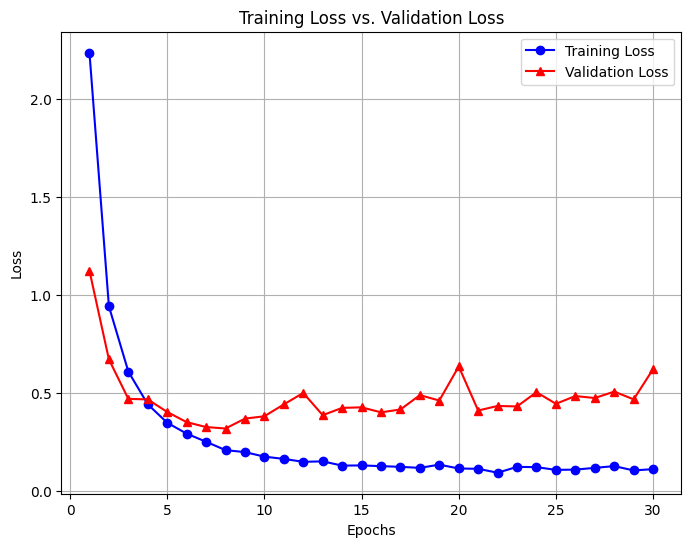

In [72]:
import matplotlib.pyplot as plt

# Extract Loss and Validation Loss from training history
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)  # Number of epochs

# Plot Training and Validation Loss
plt.figure(figsize=(8, 6))
plt.plot(epochs, train_loss, 'bo-', label='Training Loss')  # 'bo-' means blue circles with lines
plt.plot(epochs, val_loss, 'r^-', label='Validation Loss')  # 'r^-' means red triangles with lines

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs. Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [73]:
# Step 1: Get true labels from the test dataset
true_labels = validation_generator.classes

# Step 2: Get class names
class_names = list(validation_generator.class_indices.keys())

# Step 3: Get model predictions
y_pred_probs = model.predict(validation_generator)  # Predict probabilities
y_pred = np.argmax(y_pred_probs, axis=1)  # Convert probabilities to class labels

# Step 4: Compute Confusion Matrix
cm = confusion_matrix(true_labels, y_pred)

# Step 5: Calculate Precision, Recall, and F1-score for each class
precision = np.diag(cm) / (np.sum(cm, axis=0) + 1e-9)  # TP / (TP + FP)
recall = np.diag(cm) / (np.sum(cm, axis=1) + 1e-9)  # TP / (TP + FN)
f1_score = 2 * (precision * recall) / (precision + recall + 1e-9)  # Harmonic mean

# Step 6: Store results in a DataFrame
results_df = pd.DataFrame({
    "Name of Crop": class_names,
    "Accuracy": [np.trace(cm) / np.sum(cm)] * len(class_names),  # Overall accuracy
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1_score
})

# Step 7: Print the results table
print("\nResults Table:\n")
print(results_df.to_string(index=False))

# Step 8: Plot Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Step 9: Print Classification Report (Alternative for better metrics)
print("\nClassification Report:\n")
print(classification_report(true_labels, y_pred, target_names=class_names))

 90/509 ━━━━━━━━━━━━━━━━━━━━ 31s 75ms/step

KeyboardInterrupt: 